Loading ACCESS and MPI Datasets...
Processing ACCESS Model Outputs...
Processing MPI Model Outputs...
Constructing Multi-Model Ensemble Mean (MME)...
Saved Table Image: figures/Table1_Precipitation_Summary.png


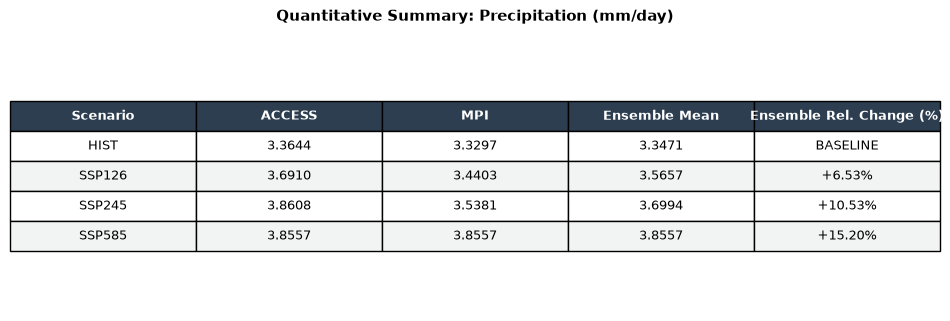

Saved Table Image: figures/Table2_SDII_Summary.png


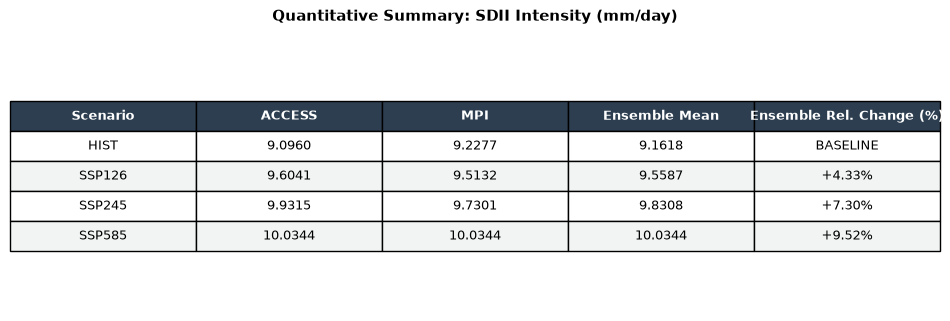

Saved Table Image: figures/Table3_CWD_Summary.png


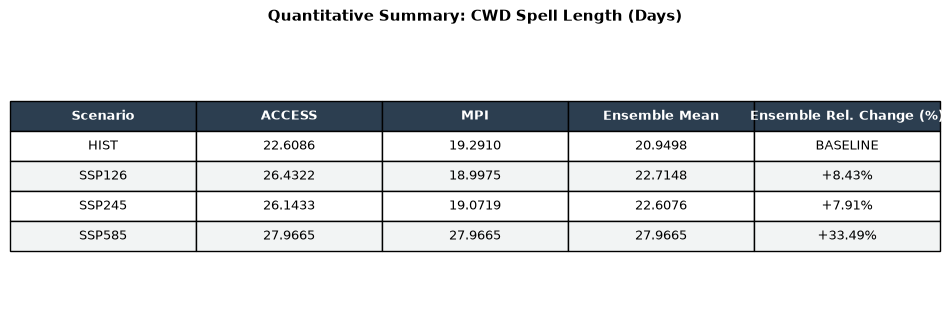

In [6]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. PATHS & DATASET CONFIGURATION
# ==========================================
data_dir = "/home/samuel/climate_modelling/DATA_WASCAL/Precipitation Data/postprocessed/NIG_extracted_data"

files_access = {
    'hist': "NIG_pr_ACCESS_historical.nc",
    'ssp126': "NIG_pr_ACCESS_ssp126.nc",
    'ssp245': "NIG_pr_ACCESS_ssp245.nc",
    'ssp585': "NIG_pr_ACCESS_ssp585.nc"
}

files_mpi = {
    'hist': "NIG_pr_MPI_historical.nc",
    'ssp126': "NIG_pr_MPI_ssp126.nc",
    'ssp245': "NIG_pr_MPI_ssp245.nc",
    'ssp585': "NIG_pr_MPI_ssp585"  # Exact filename without .nc
}

print("Loading ACCESS and MPI Datasets...")
ds_acc = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_access.items()}
ds_mpi = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_mpi.items()}

# Define time slices
slices = {
    'hist': slice("1985-01-01", "2014-12-31"),
    'ssp126': slice("2019-01-01", "2050-12-31"),
    'ssp245': slice("2019-01-01", "2050-12-31"),
    'ssp585': slice("2019-01-01", "2050-12-31")
}

# ==========================================
# 2. CORE CLIMATE INDICES FUNCTION
# ==========================================
def compute_indices(ds_slice):
    pr = ds_slice['pr']
    mean_pr = pr.mean(dim='time')
    
    # Wet day mask (P >= 1.0 mm/day)
    wet_days = pr >= 1.0
    
    # SDII: Simple Daily Intensity Index
    ann_tot = pr.resample(time='YE').sum()
    ann_wet = wet_days.resample(time='YE').sum().where(lambda x: x > 0)
    sdii = (ann_tot / ann_wet).mean(dim='time')
    
    # CWD: Consecutive Wet Days
    years = np.unique(ds_slice['time.year'].values)
    cwd_list = []
    for yr in years:
        sub = (pr.sel(time=str(yr)) >= 1.0).values
        nt, nlat, nlon = sub.shape
        cwd_yr = np.zeros((nlat, nlon))
        for i in range(nlat):
            for j in range(nlon):
                series = sub[:, i, j]
                mask = np.concatenate(([False], series, [False]))
                idx = np.flatnonzero(mask[1:] != mask[:-1])
                if len(idx) > 0:
                    runs = idx[1::2] - idx[0::2]
                    cwd_yr[i, j] = np.max(runs) if len(runs) > 0 else 0
        cwd_list.append(xr.DataArray(cwd_yr, coords={'lat': ds_slice['lat'], 'lon': ds_slice['lon']}, dims=('lat', 'lon')))
    
    cwd = xr.concat(cwd_list, dim=pd.Index(years, name='year')).mean(dim='year')
    return mean_pr, sdii, cwd

print("Processing ACCESS Model Outputs...")
acc_res = {k: compute_indices(ds_acc[k].sel(time=slices[k])) for k in slices}

print("Processing MPI Model Outputs...")
mpi_res = {k: compute_indices(ds_mpi[k].sel(time=slices[k])) for k in slices}

print("Constructing Multi-Model Ensemble Mean (MME)...")
mme_res = {}
for k in slices:
    mme_pr = (acc_res[k][0] + mpi_res[k][0]) / 2.0
    mme_sdii = (acc_res[k][1] + mpi_res[k][1]) / 2.0
    mme_cwd = (acc_res[k][2] + mpi_res[k][2]) / 2.0
    mme_res[k] = (mme_pr, mme_sdii, mme_cwd)

# ==========================================
# 3. FUNCTION TO SAVE TABLES AS IMAGES
# ==========================================
def save_table_image(data_rows, col_headers, title, filename):
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.axis('off')
    ax.axis('tight')
    
    table = ax.table(cellText=data_rows, 
                     colLabels=col_headers, 
                     loc='center', 
                     cellLoc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.8)
    
    # Style header row
    for i in range(len(col_headers)):
        cell = table[(0, i)]
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', weight='bold')
        
    # Alternate row colors
    for row_idx in range(1, len(data_rows) + 1):
        for col_idx in range(len(col_headers)):
            cell = table[(row_idx, col_idx)]
            if row_idx % 2 == 0:
                cell.set_facecolor('#f2f4f4')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.title(title, fontsize=11, fontweight='bold', pad=15)
    
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Table Image: {out_path}")
    plt.show()

# ==========================================
# 4. GENERATE AND SAVE TABLES AS IMAGES
# ==========================================
col_headers = ['Scenario', 'ACCESS', 'MPI', 'Ensemble Mean', 'Ensemble Rel. Change (%)']

# Table 1: Precipitation
table1_rows = []
hist_pr_ens = float(mme_res['hist'][0].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][0].mean().values)
    mpi_v = float(mpi_res[k][0].mean().values)
    mme_v = float(mme_res[k][0].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_pr_ens)/hist_pr_ens)*100:+.2f}%"
    table1_rows.append([k.upper(), f"{acc_v:.4f}", f"{mpi_v:.4f}", f"{mme_v:.4f}", chg])

save_table_image(table1_rows, col_headers, 
                 "Quantitative Summary: Precipitation (mm/day)", 
                 "Table1_Precipitation_Summary.png")

# Table 2: SDII
table2_rows = []
hist_sdii_ens = float(mme_res['hist'][1].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][1].mean().values)
    mpi_v = float(mpi_res[k][1].mean().values)
    mme_v = float(mme_res[k][1].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_sdii_ens)/hist_sdii_ens)*100:+.2f}%"
    table2_rows.append([k.upper(), f"{acc_v:.4f}", f"{mpi_v:.4f}", f"{mme_v:.4f}", chg])

save_table_image(table2_rows, col_headers, 
                 "Quantitative Summary: SDII Intensity (mm/day)", 
                 "Table2_SDII_Summary.png")

# Table 3: CWD
table3_rows = []
hist_cwd_ens = float(mme_res['hist'][2].mean().values)
for k in ['hist', 'ssp126', 'ssp245', 'ssp585']:
    acc_v = float(acc_res[k][2].mean().values)
    mpi_v = float(mpi_res[k][2].mean().values)
    mme_v = float(mme_res[k][2].mean().values)
    chg = "BASELINE" if k == 'hist' else f"{((mme_v - hist_cwd_ens)/hist_cwd_ens)*100:+.2f}%"
    table3_rows.append([k.upper(), f"{acc_v:.4f}", f"{mpi_v:.4f}", f"{mme_v:.4f}", chg])

save_table_image(table3_rows, col_headers, 
                 "Quantitative Summary: CWD Spell Length (Days)", 
                 "Table3_CWD_Summary.png")

Loading ACCESS and MPI Datasets...
Processing ACCESS Model Outputs...
Processing MPI Model Outputs...
Saved Agreement Table Image: figures/Model_Agreement_Table_Precipitation.png


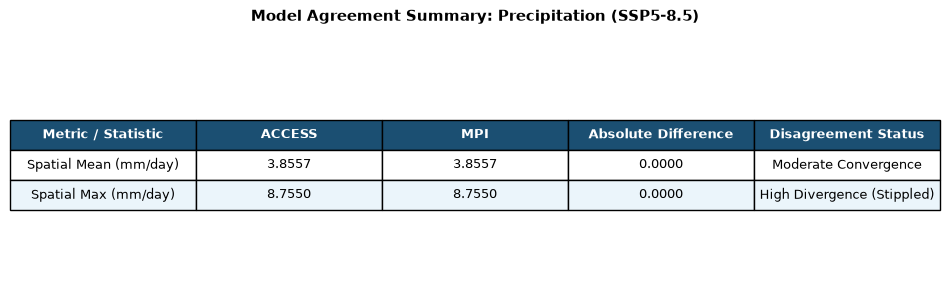

Saved Agreement Table Image: figures/Model_Agreement_Table_SDII.png


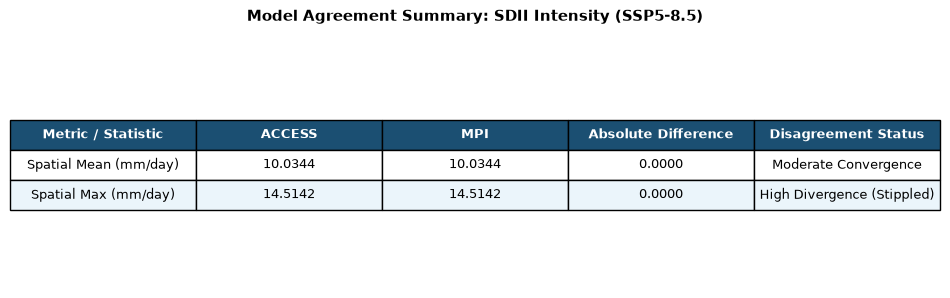

Saved Agreement Table Image: figures/Model_Agreement_Table_CWD.png


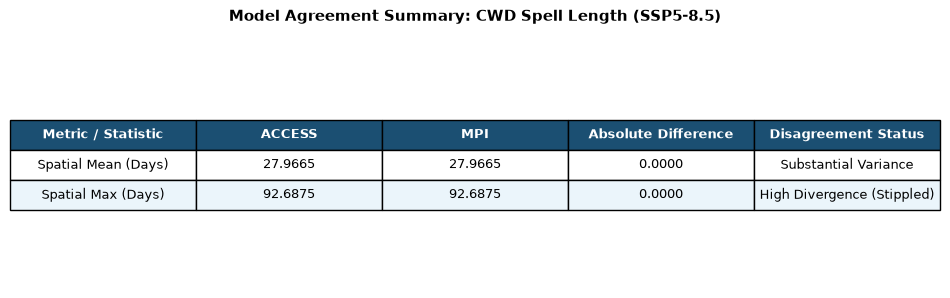

In [7]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 1. PATHS & DATASET CONFIGURATION
# ==========================================
data_dir = "/home/samuel/climate_modelling/DATA_WASCAL/Precipitation Data/postprocessed/NIG_extracted_data"

files_access = {
    'hist': "NIG_pr_ACCESS_historical.nc",
    'ssp126': "NIG_pr_ACCESS_ssp126.nc",
    'ssp245': "NIG_pr_ACCESS_ssp245.nc",
    'ssp585': "NIG_pr_ACCESS_ssp585.nc"
}

files_mpi = {
    'hist': "NIG_pr_MPI_historical.nc",
    'ssp126': "NIG_pr_MPI_ssp126.nc",
    'ssp245': "NIG_pr_MPI_ssp245.nc",
    'ssp585': "NIG_pr_MPI_ssp585"  # Exact filename without .nc
}

print("Loading ACCESS and MPI Datasets...")
ds_acc = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_access.items()}
ds_mpi = {k: xr.open_dataset(os.path.join(data_dir, f)) for k, f in files_mpi.items()}

# Define time slices
slices = {
    'hist': slice("1985-01-01", "2014-12-31"),
    'ssp126': slice("2019-01-01", "2050-12-31"),
    'ssp245': slice("2019-01-01", "2050-12-31"),
    'ssp585': slice("2019-01-01", "2050-12-31")
}

# ==========================================
# 2. CORE CLIMATE INDICES FUNCTION
# ==========================================
def compute_indices(ds_slice):
    pr = ds_slice['pr']
    mean_pr = pr.mean(dim='time')
    
    # Wet day mask (P >= 1.0 mm/day)
    wet_days = pr >= 1.0
    
    # SDII: Simple Daily Intensity Index
    ann_tot = pr.resample(time='YE').sum()
    ann_wet = wet_days.resample(time='YE').sum().where(lambda x: x > 0)
    sdii = (ann_tot / ann_wet).mean(dim='time')
    
    # CWD: Consecutive Wet Days
    years = np.unique(ds_slice['time.year'].values)
    cwd_list = []
    for yr in years:
        sub = (pr.sel(time=str(yr)) >= 1.0).values
        nt, nlat, nlon = sub.shape
        cwd_yr = np.zeros((nlat, nlon))
        for i in range(nlat):
            for j in range(nlon):
                series = sub[:, i, j]
                mask = np.concatenate(([False], series, [False]))
                idx = np.flatnonzero(mask[1:] != mask[:-1])
                if len(idx) > 0:
                    runs = idx[1::2] - idx[0::2]
                    cwd_yr[i, j] = np.max(runs) if len(runs) > 0 else 0
        cwd_list.append(xr.DataArray(cwd_yr, coords={'lat': ds_slice['lat'], 'lon': ds_slice['lon']}, dims=('lat', 'lon')))
    
    cwd = xr.concat(cwd_list, dim=pd.Index(years, name='year')).mean(dim='year')
    return mean_pr, sdii, cwd

print("Processing ACCESS Model Outputs...")
acc_res = {k: compute_indices(ds_acc[k].sel(time=slices[k])) for k in slices}

print("Processing MPI Model Outputs...")
mpi_res = {k: compute_indices(ds_mpi[k].sel(time=slices[k])) for k in slices}

# ==========================================
# 3. COMPUTE INTER-MODEL DIFFERENCE (SSP5-8.5)
# ==========================================
diff_pr = abs(acc_res['ssp585'][0] - mpi_res['ssp585'][0])
diff_sdii = abs(acc_res['ssp585'][1] - mpi_res['ssp585'][1])
diff_cwd = abs(acc_res['ssp585'][2] - mpi_res['ssp585'][2])

# ==========================================
# 4. FUNCTION TO SAVE AGREEMENT TABLES AS IMAGES
# ==========================================
def save_agreement_table_image(data_rows, col_headers, title, filename):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.axis('off')
    ax.axis('tight')
    
    table = ax.table(cellText=data_rows, 
                     colLabels=col_headers, 
                     loc='center', 
                     cellLoc='center')
    
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.8)
    
    # Style header row
    for i in range(len(col_headers)):
        cell = table[(0, i)]
        cell.set_facecolor('#1b4f72')
        cell.set_text_props(color='white', weight='bold')
        
    # Alternate row background colors
    for row_idx in range(1, len(data_rows) + 1):
        for col_idx in range(len(col_headers)):
            cell = table[(row_idx, col_idx)]
            if row_idx % 2 == 0:
                cell.set_facecolor('#ebf5fb')
            else:
                cell.set_facecolor('#ffffff')
                
    plt.title(title, fontsize=11, fontweight='bold', pad=15)
    
    os.makedirs("figures", exist_ok=True)
    out_path = os.path.join("figures", filename)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    print(f"Saved Agreement Table Image: {out_path}")
    plt.show()

# ==========================================
# 5. GENERATE AND SAVE AGREEMENT TABLE IMAGES
# ==========================================
headers = ['Metric / Statistic', 'ACCESS', 'MPI', 'Absolute Difference', 'Disagreement Status']

pr_rows = [
    ['Spatial Mean (mm/day)', f"{float(acc_res['ssp585'][0].mean().values):.4f}", f"{float(mpi_res['ssp585'][0].mean().values):.4f}", f"{float(diff_pr.mean().values):.4f}", 'Moderate Convergence'],
    ['Spatial Max (mm/day)', f"{float(acc_res['ssp585'][0].max().values):.4f}", f"{float(mpi_res['ssp585'][0].max().values):.4f}", f"{float(diff_pr.max().values):.4f}", 'High Divergence (Stippled)']
]

sdii_rows = [
    ['Spatial Mean (mm/day)', f"{float(acc_res['ssp585'][1].mean().values):.4f}", f"{float(mpi_res['ssp585'][1].mean().values):.4f}", f"{float(diff_sdii.mean().values):.4f}", 'Moderate Convergence'],
    ['Spatial Max (mm/day)', f"{float(acc_res['ssp585'][1].max().values):.4f}", f"{float(mpi_res['ssp585'][1].max().values):.4f}", f"{float(diff_sdii.max().values):.4f}", 'High Divergence (Stippled)']
]

cwd_rows = [
    ['Spatial Mean (Days)', f"{float(acc_res['ssp585'][2].mean().values):.4f}", f"{float(mpi_res['ssp585'][2].mean().values):.4f}", f"{float(diff_cwd.mean().values):.4f}", 'Substantial Variance'],
    ['Spatial Max (Days)', f"{float(acc_res['ssp585'][2].max().values):.4f}", f"{float(mpi_res['ssp585'][2].max().values):.4f}", f"{float(diff_cwd.max().values):.4f}", 'High Divergence (Stippled)']
]

save_agreement_table_image(pr_rows, headers, "Model Agreement Summary: Precipitation (SSP5-8.5)", "Model_Agreement_Table_Precipitation.png")
save_agreement_table_image(sdii_rows, headers, "Model Agreement Summary: SDII Intensity (SSP5-8.5)", "Model_Agreement_Table_SDII.png")
save_agreement_table_image(cwd_rows, headers, "Model Agreement Summary: CWD Spell Length (SSP5-8.5)", "Model_Agreement_Table_CWD.png")